# 04 · Findings and recommendations

Previous: [03 Modeling](03_modeling.ipynb)

This notebook re-fits the chosen model (logistic regression, C = 10, the winner in notebook 03) and uses it to answer the original question in plain language.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wellbeing.config import Settings
from wellbeing.data import CLASSES, TARGET, add_target, clean, feature_frame, load_raw

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Low": "#d1495b", "Medium": "#edae49", "High": "#2e86ab"}  # one colour per wellbeing group, reused everywhere

# Settings points at the CSV and names every column; the notebooks run from the notebooks/ folder
s = Settings(data_file=Path("../data/social_media_addiction_mental_wellbeing.csv"))
from wellbeing import analysis, modeling
from wellbeing.pipeline import TunedModel

df, _ = clean(load_raw(s), s)
df, cuts = add_target(df, s)
X = feature_frame(df, s)
X_train, X_test, y_train, y_test = modeling.split(df, X, s)

from sklearn.linear_model import LogisticRegression
pipe = modeling.make_pipeline(X_train, LogisticRegression(C=10, max_iter=2000, random_state=s.random_state), s).fit(X_train, y_train)
model = TunedModel(pipe, np.ones(3))  # default thresholds: tuning was not adopted in notebook 03
m = modeling.metrics(y_test, model.predict(X_test), model.predict_proba(X_test), CLASSES)
print(f"Test macro-F1 {m['f1_macro']}, accuracy {m['accuracy']}, ROC AUC {m['roc_auc_ovr']}")

Test macro-F1 0.6527, accuracy 0.6533, ROC AUC 0.8382


## Finding 1 · More hours go with lower wellbeing, gradually
With everything else held at what the model sees in real people, here is the model's average predicted chance of each group if everyone used social media for a given number of hours.

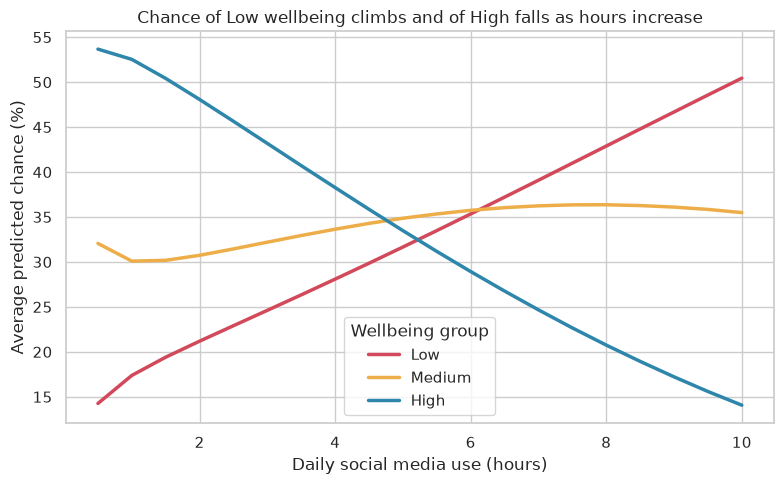

In [2]:
grid = [round(float(v), 1) for v in np.arange(0.5, 10.01, 0.5)]
pdp = analysis.partial_dependence(model, X_test, s.hours_column, grid)

fig, ax = plt.subplots(figsize=(8, 5))
for c in CLASSES:
    ax.plot(pdp["grid"], pdp["prob_pct"][c], label=c, color=PALETTE[c], lw=2.5)
ax.set_xlabel("Daily social media use (hours)")
ax.set_ylabel("Average predicted chance (%)")
ax.set_title("Chance of Low wellbeing climbs and of High falls as hours increase")
ax.legend(title="Wellbeing group")
plt.tight_layout()
plt.show()

## Finding 2 · Late-night use is a strong marker

In [3]:
night = analysis.night_effect(model, X_test, s)
observed = pd.crosstab(df[s.night_column], df[TARGET], normalize="index").reindex(columns=CLASSES) * 100

print("Observed share of people in each group (%):")
display(observed.round(1))
print("Model: average chance of each group if everyone did / did not use it late at night (%):")
display(pd.DataFrame(night).T.round(1))

Observed share of people in each group (%):


wellbeing_class,Low,Medium,High
late_night_usage,,,
No,21.4,31.5,47.0
Yes,42.6,31.4,26.0


Model: average chance of each group if everyone did / did not use it late at night (%):


,Low,Medium,High
Yes,40.2,33.1,26.7
No,19.5,32.8,47.7


## Finding 3 · Habits matter more than hours

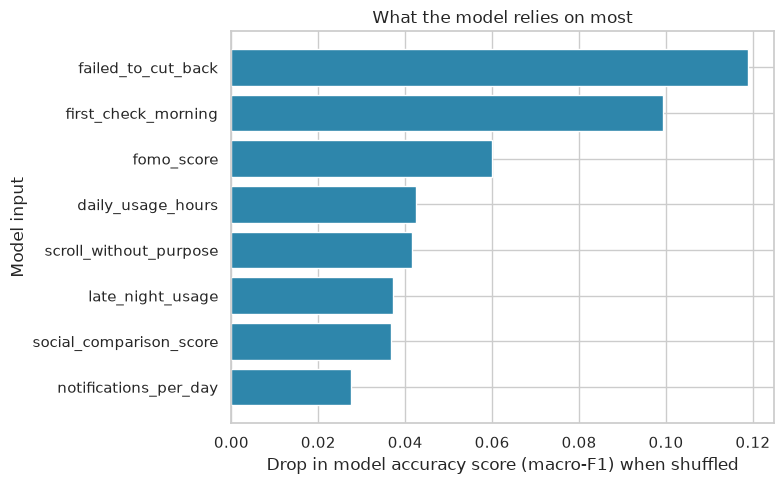

In [4]:
imp = pd.DataFrame(analysis.importance(model, X_test, y_test, s)).head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp["feature"], imp["importance"], color="#2e86ab")
ax.set_xlabel("Drop in model accuracy score (macro-F1) when shuffled")
ax.set_ylabel("Model input")
ax.set_title("What the model relies on most")
plt.tight_layout()
plt.show()

# Summary of findings (plain language)

| # | Finding | Evidence |
|---|---|---|
| 1 | **The more hours people spend on social media each day, the lower their wellbeing tends to be**, gradually, with no sharp "danger" threshold. | Under 2 h/day: 17% in the Low group; 8+ h: 48%. |
| 2 | **Using social media late at night is a strong warning sign.** | 43% Low among late-night users vs 21% among others. |
| 3 | **How people use it matters more than how long.** Unsuccessfully trying to cut back, checking within minutes of waking, and fear of missing out rank highest. | Model importance (above). |
| 4 | **Age, gender and platform tell us little.** | Age groups differ by under half a point of wellbeing. |
| 5 | **The model is useful but not precise.** It places about two in three people in the right group. | Test macro-F1 0.65 vs 0.17 for guessing. |

> **Important:** this is a single survey. It shows that these things *go together*; it does **not** prove social media *causes* lower wellbeing. People who feel low may also use social media differently.

# Recommendations
**For platforms and advertisers**
1. Reduce ad delivery late at night, and cap how many times one person sees an ad per day.
2. Avoid targeting people showing signs of compulsive use (repeated failed attempts to cut back).
3. Avoid FOMO / comparison-style creative.
4. Track wellbeing signals (opt-outs, reports, short surveys) next to sales results.

**For policy makers and platform design**
1. Guidance should name late-night and heavy daily use directly, not just age.
2. Default quiet hours and easy daily-limit tools, as nudges, not bans.
3. Make help easy for people who can't cut back.

# Next steps
* **Test cause and effect**: follow the same people over time, or run a study where some people reduce late-night use.
* **Collect more detail**: what people do on social media (not just how long), plus mental-health history.
* **Check generalisation**: this survey has 1,500 people; repeat with a larger, more representative sample.
* **Pilot** the late-night quiet-hours idea and measure the change in wellbeing.
* **Try richer models** (e.g. gradient boosting) once more data is available; with this much data, simple models were as good as complex ones.